# 2. Aşama — Açıklamalı Çalışma Notebook'u (TESLİM EDİLMEZ)

Bu dosya sadece senin öğrenmen için. Her bölümde:
1. kısa açıklama
2. **küçük bir örnek** (önce minik bir tabloda dene, sonra gerçek veride)
3. **hoca sorarsa** ne diyeceğin

Hücreleri yukarıdan aşağıya sırayla çalıştır. Her çıktıya bak, "neden böyle çıktı?" diye düşün.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# küçük örnek tablo: 6 rezervasyon (2. ve 3. satır birebir aynı)
ornek = pd.DataFrame({
    "otel":    ["City", "Resort", "Resort", "City", "City", "Resort"],
    "ulke":    ["PRT", "GBR", "GBR", None, "PRT", "PRT"],
    "acente":  [9, None, None, 240, 9, None],
    "cocuk":   [0, 1, 1, None, 2, 0],
    "sure":    [10, 200, 200, 45, 5, 120],
    "iptal":   [0, 1, 1, 0, 0, 1],
})
ornek

,otel,ulke,acente,cocuk,sure,iptal
0,City,PRT,9.0,0.0,10,0
1,Resort,GBR,NaN,1.0,200,1
2,Resort,GBR,NaN,1.0,200,1
3,City,NaN,240.0,NaN,45,0
4,City,PRT,9.0,2.0,5,0
5,Resort,PRT,NaN,0.0,120,1


---
## 1. `shape`, `duplicated`, `drop_duplicates`

- **`shape`**: tablonun boyutu → `(satır sayısı, sütun sayısı)`. Parantez yok, çünkü fonksiyon değil, bir **özellik**.
- **`duplicated()`**: her satır için "bu satır daha önce birebir aynısıyla geçti mi?" diye **True/False** verir.
  `.sum()` ile True'ları sayarız (True = 1, False = 0).
- **`drop_duplicates()`**: tekrar eden satırları siler, **ilk** görüleni bırakır.
  Yeni tablo döndürür, eskisini değiştirmez; bu yüzden `df = df.drop_duplicates()` diye geri atarız.

In [2]:
print("boyut:", ornek.shape)                 # (6, 6) -> 6 satır, 6 sütun
print(ornek.duplicated())                    # 2. satır (index 2) True çünkü 1. satırın aynısı
print("tekrar eden:", ornek.duplicated().sum())

temiz = ornek.drop_duplicates()
print("silindikten sonra boyut:", temiz.shape)

boyut: (6, 6)
0    False
1    False
2     True
3    False
4    False
5    False
dtype: bool
tekrar eden: 1
silindikten sonra boyut: (5, 6)


> **Hoca sorarsa:** *Neden tekrar eden satırları sildin?*
>
> **Cevap:** Aynı satır hem eğitim hem test verisine düşerse model o satırı eğitimde zaten görmüş olur. Test sınavında çalıştığı soru gelmiş gibi olur, skor olduğundan yüksek çıkar. Silmeden önce F1 %85'ti, silince %70 oldu; %70 gerçek başarı.

---
## 2. `company %94 boş` ve `df.drop(columns=...)`

**"company %94 boş" ne demek:** `company` sütunu rezervasyonu yapan şirketin numarası. 100 satırın 94'ünde bu hücre **boş**
(çünkü çoğu müşteri bireysel, şirket yok). Bu kadar boş bir sütundan model bir şey öğrenemez; bu yüzden **sütunu tamamen siliyoruz.**

**`df.drop(columns=[...])`**: verilen sütunları siler. `columns=` "sütun sil" demek (yazmazsan satır silmeye çalışır).

Aynı satırda `reservation_status` ve `reservation_status_date` da siliniyor: bunlar rezervasyonun **sonucunu**
(iptal edildi / geldi) gösteriyor. Tahmin anında bu bilgi yok. Modele verirsek cevabı kopya çekmiş olur → **veri sızıntısı**.

In [3]:
print("silmeden önce sütunlar:", list(ornek.columns))
ornek2 = ornek.drop(columns=["acente"])
print("sildikten sonra       :", list(ornek2.columns))

silmeden önce sütunlar: ['otel', 'ulke', 'acente', 'cocuk', 'sure', 'iptal']
sildikten sonra       : ['otel', 'ulke', 'cocuk', 'sure', 'iptal']


> **Hoca sorarsa:** *reservation_status'u neden sildin?*
>
> **Cevap:** Rezervasyonun sonucunu gösteriyor: Canceled ise iptal edilmiş. Yani tahmin etmeye çalıştığımız şeyin kendisi. Gerçek hayatta rezervasyon yapılırken bu bilgi henüz yok. Bırakırsam model %100'e yakın çıkar ama hiçbir işe yaramaz.

---
## 3. `fillna` ve "agent boşsa acente yok demek"

**`fillna(deger)`**: boş hücreleri (NaN) verilen değerle doldurur.

- **agent** = rezervasyonu yapan seyahat acentesinin numarası. Boşsa bu bir hata değil: müşteri **acente kullanmamış**.
  Bu yüzden 0 yazıyoruz; 0 = "acente yok". (Veride 0 numaralı acente yok, karışmaz.)
- **children** = çocuk sayısı. Sadece 4 satırda boş. Çoğu rezervasyonda çocuk yok, o yüzden 0 en mantıklı tahmin.

In [4]:
print("acente önce:", ornek["acente"].tolist())
print("acente sonra:", ornek["acente"].fillna(0).tolist())
print("cocuk önce:", ornek["cocuk"].tolist())
print("cocuk sonra:", ornek["cocuk"].fillna(0).tolist())

acente önce: [9.0, nan, nan, 240.0, 9.0, nan]
acente sonra: [9.0, 0.0, 0.0, 240.0, 9.0, 0.0]
cocuk önce: [0.0, 1.0, 1.0, nan, 2.0, 0.0]
cocuk sonra: [0.0, 1.0, 1.0, 0.0, 2.0, 0.0]


> **Hoca sorarsa:** *Neden boşları ortalama ile doldurmadın?*
>
> **Cevap:** agent bir numara (kimlik), ortalaması anlamsız; boşluk 'acente yok' demek, o yüzden 0. children'da ortalama 0,1 gibi bir şey çıkar, '0,1 çocuk' olmaz.

---
## 4. `mean`

**`mean()`** ortalama. 0 ve 1'lerden oluşan bir sütunun ortalaması **1'lerin oranıdır**.
`is_canceled` 0/1 olduğu için `df["is_canceled"].mean()` doğrudan **iptal oranını** verir.

In [5]:
print(ornek["iptal"].tolist())
print("ortalama:", ornek["iptal"].mean())    # 3 tane 1 / 6 satır = 0.5 -> %50 iptal

[0, 1, 1, 0, 0, 1]
ortalama: 0.5


---
## 5. `train_test_split`, `stratify=y`, `random_state=42`

Veriyi ikiye ayırıyoruz:
- **eğitim (%80)**: model sadece buradan öğrenir
- **test (%20)**: model bunu hiç görmez, en sonda sınav gibi kullanılır

Parametreler:
| | ne yapar |
|---|---|
| `test_size=0.2` | %20 teste |
| `random_state=42` | ayırma rastgele; bu sayı sayesinde **her çalıştırmada aynı** ayrım gelir (42 özel değil, herhangi bir sabit sayı olur) |
| `stratify=y` | iptal oranı eğitimde ve testte **aynı** kalır |

`X` = modelin baktığı sütunlar (öznitelikler), `y` = tahmin edilecek sütun (`is_canceled`).

In [6]:
from sklearn.model_selection import train_test_split

# 20 satırlık örnek: 5 iptal (%25)
y_ornek = pd.Series([1]*5 + [0]*15)
X_ornek = pd.DataFrame({"sure": range(20)})

for st in [None, y_ornek]:
    Xe, Xt, ye, yt = train_test_split(X_ornek, y_ornek, test_size=0.2, random_state=6, stratify=st)
    print("stratify =", "yok" if st is None else "y", "-> test iptal oranı:", yt.mean())

stratify = yok -> test iptal oranı: 0.0
stratify = y -> test iptal oranı: 0.25


Veride iptal oranı %25. stratify olmadan test kümesine hiç iptal düşmedi (%0), yani model iptalleri hiç sınanmadı. `stratify=y` ile test kümesi de tam %25.

> **Hoca sorarsa:** *stratify=y ne işe yarıyor?*
>
> **Cevap:** Veride iptaller %27,5. stratify olmasa test kümesine şans eseri daha az ya da daha çok iptal düşebilir, sonuç yanıltır. stratify=y eğitimde de testte de iptal oranını %27,5 tutuyor.

---
## 6. `.copy()`, `.mode()[0]`, `fillna(ulke_modu)`

- **`X_egitim.copy()`**: tablonun ayrı bir kopyasını alır. `train_test_split`'ten gelen tablo, ana tablonun
  bir parçası gibi davranabilir; üzerinde değişiklik yapınca pandas uyarı verir. `.copy()` ile güvenle değiştiririz.
- **`.mode()`**: en sık görülen değer(ler). Birden fazla değer eşit sıklıkta olabilir, bu yüzden liste gibi döner;
  **`[0]`** ilkini alır.
- **`fillna(ulke_modu)`**: boş ülkeleri en sık ülkeyle doldurur (örnekte de gerçek veride de PRT, yani Portekiz).

**Neden sadece eğitimden?** 8. haftadaki kural: boşları doldururken kullandığın değeri **eğitim verisinden** hesapla.
Test verisinden bir şey öğrenirsek test "görülmüş" olur = sızıntı.

In [7]:
print(ornek["ulke"].tolist())
print("mode():", ornek["ulke"].mode().tolist())
print("mode()[0]:", ornek["ulke"].mode()[0])
print("doldurulmuş:", ornek["ulke"].fillna(ornek["ulke"].mode()[0]).tolist())

['PRT', 'GBR', 'GBR', nan, 'PRT', 'PRT']
mode(): ['PRT']
mode()[0]: PRT
doldurulmuş: ['PRT', 'GBR', 'GBR', 'PRT', 'PRT', 'PRT']


---
## 7. Frekans kodlama: `value_counts(normalize=True)` ve `.map(...).fillna(0)`

`country` 177 farklı ülke. One-hot yapsak 176 yeni sütun açılır. Bunun yerine her ülkeyi **görülme oranıyla** değiştiriyoruz.

- **`value_counts()`**: her değerin kaç kez geçtiğini sayar.
- **`normalize=True`**: sayı yerine **oran** verir (hepsinin toplamı 1).
- **`.map(ulke_frekans)`**: her ülkeyi o tablodaki karşılığıyla değiştirir (PRT → 0.4 gibi).
- **`.fillna(0)`**: test verisinde, eğitimde **hiç görülmemiş** bir ülke olabilir; map onu bulamaz ve boş bırakır → 0 yazıyoruz.

In [8]:
egitim_ulke = pd.Series(["PRT", "PRT", "GBR", "PRT", "FRA"])
test_ulke = pd.Series(["GBR", "PRT", "JPN"])          # JPN eğitimde yok

frek = egitim_ulke.value_counts(normalize=True)
print(frek)                                           # PRT 0.6, GBR 0.2, FRA 0.2
print("map:", test_ulke.map(frek).tolist())           # JPN -> NaN
print("map + fillna(0):", test_ulke.map(frek).fillna(0).tolist())

PRT    0.6
GBR    0.2
FRA    0.2
Name: proportion, dtype: float64
map: [0.2, 0.6, nan]
map + fillna(0): [0.2, 0.6, 0.0]


---
## 8. Encoding, one-hot, `get_dummies`, `drop_first=True`, `dtype=int`, `tolist`, `reindex`

- **Encoding (kodlama):** metni sayıya çevirmek. Model sadece sayı anlar.
- **One-hot encoding:** her kategori için ayrı bir 0/1 sütunu. Her satırda sadece bir tane 1 olur.
  Sırası olmayan kategoriler için (otel türü, yemek paketi). "City=1, Resort=2" deseydik model sahte bir büyüklük sırası öğrenirdi.
- **`pd.get_dummies(...)`**: one-hot'u yapan pandas fonksiyonu.
- **`drop_first=True`**: ilk kategorinin sütununu atar. 2 kategori varsa tek sütun yeter (City değilse Resort'tur).
- **`dtype=int`**: True/False yerine 1/0 yazar.
- **`.tolist()`**: sonucu normal Python listesine çevirir (yazdırması kolay).
- **`reindex(columns=..., fill_value=0)`**: test tablosunun sütunlarını eğitimdekiyle **aynı sıraya ve aynı listeye** getirir.
  Testte hiç görülmeyen bir kategori varsa o sütun eksik kalır; reindex onu 0 ile ekler. Model eğitimde gördüğü sütunları bekler.

In [9]:
print("metin sütunlar:", ornek.select_dtypes(include=["object", "string"]).columns.tolist())

print(pd.get_dummies(ornek[["otel"]], dtype=int))                    # iki sütun
print(pd.get_dummies(ornek[["otel"]], drop_first=True, dtype=int))   # tek sütun yeter

metin sütunlar: ['otel', 'ulke']
   otel_City  otel_Resort
0          1            0
1          0            1
2          0            1
3          1            0
4          1            0
5          0            1
   otel_Resort
0            0
1            1
2            1
3            0
4            0
5            1


In [10]:
egitim = pd.get_dummies(pd.DataFrame({"yemek": ["BB", "HB", "FB"]}), dtype=int)
test = pd.get_dummies(pd.DataFrame({"yemek": ["BB", "BB"]}), dtype=int)
print("eğitim sütunları:", egitim.columns.tolist())
print("test sütunları  :", test.columns.tolist())          # eksik!
print(test.reindex(columns=egitim.columns, fill_value=0))  # artık aynı

eğitim sütunları: ['yemek_BB', 'yemek_FB', 'yemek_HB']
test sütunları  : ['yemek_BB']
   yemek_BB  yemek_FB  yemek_HB
0         1         0         0
1         1         0         0


---
## 9. `StandardScaler`

Sütunların büyüklükleri çok farklı: `lead_time` 0–737, `adults` 0–4. Uzaklığa bakan modeller (KNN) ve lojistik regresyon
büyük sayılı sütunu daha önemli sanır. **StandardScaler** her sütunu **ortalaması 0, standart sapması 1** olacak şekilde dönüştürür:

`yeni değer = (değer − ortalama) / standart sapma`

- **`fit`**: ortalamayı ve standart sapmayı **öğrenir** → sadece **eğitim** verisiyle!
- **`transform`**: öğrendiği kuralla dönüştürür → eğitim ve test ikisine de.

Ağaç modelleri (Karar Ağacı, Random Forest) "sure > 100 mü?" gibi tek sütuna soru sorar, ölçekten etkilenmez; onlara ölçeksiz veri verdik.

In [11]:
from sklearn.preprocessing import StandardScaler

egitim = pd.DataFrame({"sure": [10, 50, 90]})
test = pd.DataFrame({"sure": [50, 200]})

olc = StandardScaler()
olc.fit(egitim)                         # ortalama 50'yi eğitimden öğrendi
print("öğrenilen ortalama:", olc.mean_)
print("eğitim ->", olc.transform(egitim).ravel().round(2))
print("test   ->", olc.transform(test).ravel().round(2))   # 50 -> 0, çünkü eğitimin ortalaması

öğrenilen ortalama: [50.]
eğitim -> [-1.22  0.    1.22]
test   -> [0.   4.59]


> **Hoca sorarsa:** *Ölçekleyiciyi neden sadece eğitim verisine fit ettin?*
>
> **Cevap:** fit ortalamayı ve standart sapmayı öğreniyor. Tüm veriye fit etseydim test verisinin ortalaması da hesaba girerdi; model test hakkında önceden bilgi almış olurdu. Buna veri sızıntısı denir. Notebook'ta kontrol de var: ölçekleyicinin öğrendiği lead_time ortalaması, eğitim verisinin ortalamasıyla aynı (79,83).

---
## 10. `def metrikler(...)`, `round`, accuracy / precision / recall / F1

- **`def`**: kendi fonksiyonumuzu yazıyoruz. `metrikler(gercek, tahmin)` dört metriği bir liste olarak verir.
  Her model için aynı dört satırı tekrar yazmamak için.
- **`round(x, 3)`**: virgülden sonra 3 basamağa yuvarlar.

Matristen hatırla: **TP** doğru bilinen iptal, **FP** yanlış alarm, **FN** kaçırılan iptal, **TN** doğru bilinen "iptal yok".

| metrik | formül | otel için soru |
|---|---|---|
| **accuracy** | doğru / toplam | genel olarak ne kadar doğru? |
| **precision** | TP / (TP + FP) | "iptal edecek" dediklerimin kaçı gerçekten iptal etti? |
| **recall** | TP / (TP + FN) | gerçek iptallerin kaçını yakaladım? |
| **F1** | 2·P·R / (P + R) | precision ve recall'un dengeli ortalaması |

In [12]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def metrikler(gercek, tahmin):
    return [round(accuracy_score(gercek, tahmin), 3), round(precision_score(gercek, tahmin), 3),
            round(recall_score(gercek, tahmin), 3), round(f1_score(gercek, tahmin), 3)]

gercek = [1, 1, 1, 1, 0, 0, 0, 0, 0, 0]    # 4 iptal
tahmin = [1, 1, 1, 0, 1, 0, 0, 0, 0, 0]    # 3 iptali yakaladı (TP=3), 1 kaçırdı (FN=1), 1 yanlış alarm (FP=1)
print(metrikler(gercek, tahmin))
print("elle precision: 3 / (3+1) =", 3 / 4)
print("elle recall   : 3 / (3+1) =", 3 / 4)

[0.8, 0.75, 0.75, 0.75]
elle precision: 3 / (3+1) = 0.75
elle recall   : 3 / (3+1) = 0.75


> **Hoca sorarsa:** *Neden sadece accuracy'ye bakmadın?*
>
> **Cevap:** Veride iptal edilmeyenler çok daha fazla (%72,5). Herkese 'iptal etmez' diyen hiçbir şey öğrenmemiş bir model bile %72,5 accuracy alır ama tek bir iptali bile yakalayamaz. Precision ve recall hangi hatayı yaptığımızı gösteriyor.

---
## 11. `modeller` sözlüğü ve `for` döngüsü

- **Sözlük `{ "ad": model }`**: her modelin adını ve kendisini bir arada tutar.
- **`modeller.items()`**: döngüde hem adı (`ad`) hem modeli (`model`) birlikte verir.
- **`if ad in olcekli_modeller`**: model bu listedeyse ölçekli veriyle, değilse ölçeksiz veriyle eğitilir.
- **`fit`** öğren, **`predict`** tahmin et (6. haftadaki oluştur → fit → predict kalıbı).
- **`sonuclar[ad] = ...`**: her modelin metriklerini sözlüğe ekler.

Modeller:
| model | kısaca | parametre |
|---|---|---|
| Lojistik Regresyon | olasılık veren S eğrisi | `max_iter=5000`: öğrenme için en fazla 5000 adım |
| KNN | en yakın 5 komşunun çoğunluğu | `n_neighbors=5` |
| Karar Ağacı | evet/hayır soruları | `random_state=42` |
| Naive Bayes | olasılık hesabı, sütunları bağımsız sayar | yok |
| Random Forest | 100 ağacın oylaması | `n_estimators=100` |

In [13]:
for ad, sayi in {"elma": 3, "armut": 5}.items():
    if ad in ["elma"]:
        print(ad, "listede var ->", sayi)
    else:
        print(ad, "listede yok ->", sayi)

elma listede var -> 3
armut listede yok -> 5


---
## 12. `pd.DataFrame(...).T`, `sort_values`, `[::-1]`, `barh`

- **`pd.DataFrame(sonuclar, index=[...])`**: sözlüğü tabloya çevirir. Modeller sütunlarda, metrikler satırlarda olur.
- **`.T`**: tabloyu **çevirir** (satır ↔ sütun). Artık her satır bir model.
- **`sort_values(["F1", "Recall"], ascending=False)`**: önce F1'e göre büyükten küçüğe, eşitse Recall'a göre.
- **`[::-1]`**: listeyi **ters çevirir**. `barh` en alttan başlayarak çizdiği için, en iyi model en üstte görünsün diye.

In [14]:
s = {"A": [0.8, 0.6], "B": [0.9, 0.7]}
t = pd.DataFrame(s, index=["Accuracy", "F1"])
print(t)
print(t.T)
print(t.T.sort_values("F1", ascending=False))
print([1, 2, 3][::-1])

            A    B
Accuracy  0.8  0.9
F1        0.6  0.7
   Accuracy   F1
A       0.8  0.6
B       0.9  0.7
   Accuracy   F1
B       0.9  0.7
A       0.8  0.6
[3, 2, 1]


> **Hoca sorarsa:** *Ben derste Recall'a göre sıraladım, sen neden F1'e göre sıraladın?*
>
> **Cevap:** Kanserde tümörü kaçırmak çok tehlikeli, o yüzden recall önemliydi. Otelde iki hata da para kaybettiriyor: kaçan iptal boş oda, yanlış alarm odayı iki kişiye satmak. Recall'a göre sıralasaydım Naive Bayes seçilirdi; recall'ı %80 ama precision'ı %41, yani 'iptal edecek' dediklerinin yarısından fazlası yanlış. F1 ikisini dengelediği için onu seçtim.

---
## 13. Random Forest parametreleri

- **`n_estimators=100`**: 100 karar ağacı kurulur, her biri verinin biraz farklı bir parçasıyla eğitilir; sonuç ağaçların **oylamasıyla** belirlenir.
- **`random_state=42`**: her çalıştırmada aynı ağaçlar → aynı sonuç.
- **`criterion="gini"`**: ağacın soruyu seçerken "bu soru grupları ne kadar iyi ayırıyor?" diye baktığı ölçü (varsayılan).
- **`max_depth=None`**: ağaçların derinliği sınırsız (varsayılan).

> **Hoca sorarsa:** *Neden Random Forest?*
>
> **Cevap:** Beş modeli aynı ayrımla denedim, F1'i en yüksek olan (0,704) Random Forest oldu. Tek bir karar ağacı ezberliyor; 100 ağacın oylaması bu sorunu azaltıyor. Ayrıca ölçeklemeye ihtiyaç duymuyor ve hangi sütunun önemli olduğunu gösterebiliyor.

---
## 14. `classification_report`, `confusion_matrix`, `ConfusionMatrixDisplay`, `ravel`

- **`classification_report`**: her sınıf için precision, recall, F1'i tek tabloda yazar. `support` = o sınıftan kaç örnek var.
- **`confusion_matrix`**: 2×2 tablo
  ```
  [[TN FP]
   [FN TP]]
  ```
- **`ConfusionMatrixDisplay(...).plot(cmap="Blues")`**: matrisi renkli kutular olarak çizer. Koyu = çok.
- **`plt.savefig("...png")`**: grafiği dosyaya kaydeder (rapora koymak için).
- **`matris.ravel()`**: 2×2 tabloyu düz bir listeye çevirir → `tn, fp, fn, tp` diye dört değişkene açarız.

[[5 1]
 [1 3]]
TN 5 FP 1 FN 1 TP 3


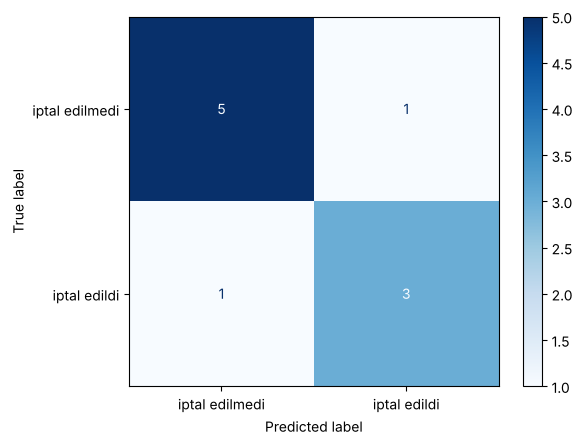

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

gercek = [1, 1, 1, 1, 0, 0, 0, 0, 0, 0]
tahmin = [1, 1, 1, 0, 1, 0, 0, 0, 0, 0]
matris = confusion_matrix(gercek, tahmin)
print(matris)
tn, fp, fn, tp = matris.ravel()
print("TN", tn, "FP", fp, "FN", fn, "TP", tp)

ConfusionMatrixDisplay(matris, display_labels=["iptal edilmedi", "iptal edildi"]).plot(cmap="Blues")
plt.show()

**Senin projendeki matris:** TN 11.726, FP 949, **FN 1.682**, TP 3.123

- Test verisinde 4.805 iptal var; model 3.123'ünü yakalamış, **1.682'sini kaçırmış** → recall = 3123 / 4805 = 0,65
- Model 4.072 kez "iptal edecek" demiş; 3.123'ünde haklı → precision = 3123 / 4072 = 0,77
- **En çok karışan:** iptal edilen rezervasyonların "iptal edilmedi" sanılması (FN > FP).
  Sebep: veride iptal edilmeyenler daha çok, model o tarafa kayıyor.

---
## 15. `predict_proba`, `[:, 1]`, eşik, `astype(int)`

- **`predict_proba`**: her satır için iki olasılık verir: `[iptal etmeme olasılığı, iptal etme olasılığı]`.
- **`[:, 1]`**: "tüm satırlar, 1. sütun" → sadece **iptal olasılığı**.
- **`olasiliklar >= 0.4`**: olasılığı 0,4 ve üstü olanlara True der.
- **`.astype(int)`**: True/False → 1/0.

Varsayılan eşik 0,5. Eşiği düşürünce model daha kolay "iptal" der: **recall artar, precision düşer.**

In [16]:
import numpy as np
olasiliklar = np.array([0.9, 0.45, 0.35, 0.2])
for esik in [0.5, 0.4, 0.3]:
    print("eşik", esik, "->", (olasiliklar >= esik).astype(int))

eşik 0.5 -> [1 0 0 0]
eşik 0.4 -> [1 1 0 0]
eşik 0.3 -> [1 1 1 0]


> **Hoca sorarsa:** *Eşiği neden değiştirdin?*
>
> **Cevap:** Model iptallerin bir kısmını kaçırıyordu (FN çok). Eşiği 0,4'e indirince recall 0,65'ten 0,76'ya çıktı, precision 0,77'den 0,70'e düştü; F1 0,704'ten 0,728'e yükseldi. Raporda ana sonuç olarak varsayılan 0,5'i verdim, 0,4'ü iyileştirme denemesi olarak gösterdim.

---
## 16. `feature_importances_`, `pd.Series`, `tail(8)`

- **`rf.feature_importances_`**: Random Forest her sütunun kararlara ne kadar katkı verdiğini hesaplar (hepsinin toplamı 1).
- **`pd.Series(..., index=X_egitim.columns)`**: bu sayıları sütun adlarıyla eşleştirir.
- **`sort_values().tail(8)`**: küçükten büyüğe sıralar, **son 8'ini** (en önemlileri) alır.

Sonuç: en önemli `lead_time` (rezervasyonun kaç gün önce yapıldığı). 1. aşamada da erken rezervasyonların daha çok iptal edildiğini görmüştük.

In [17]:
s = pd.Series([0.05, 0.40, 0.15, 0.40], index=["a", "b", "c", "d"])
print(s.sort_values())
print(s.sort_values().tail(2))

a    0.05
c    0.15
b    0.40
d    0.40
dtype: float64
b    0.4
d    0.4
dtype: float64


---
## Kendini dene (cevapları yukarıda)

1. `duplicated().sum()` ne verir?
2. Ölçekleyiciyi test verisine de fit etseydin ne olurdu?
3. `stratify=y` olmasa ne olabilirdi?
4. Precision ile recall arasındaki fark ne? Otel örneğiyle anlat.
5. Matriste FN 1.682 ne demek?
6. Neden F1'e göre sıraladın?
7. 1. aşamada %80 demiştin, neden %70?